In [80]:
import numpy as np
import os
import matplotlib.pyplot as plt

In [81]:


def fitness(chromosome, values):
    return np.dot(chromosome, values)

def repair(chromosome, weights, values, capacity):
    total_weight = np.dot(chromosome, weights)
    if total_weight <= capacity:
        return chromosome
    
    idx = np.where(chromosome == 1)[0]
    ratios = values[idx] / weights[idx]
    sorted_idx = idx[np.argsort(ratios)]  
    for i in sorted_idx:
        chromosome[i] = 0
        total_weight = np.dot(chromosome, weights)
        if total_weight <= capacity:
            break
    return chromosome

def generate_population(values, weights, capacity, pop_size):
    n = len(values)
    population = []
    for _ in range(pop_size):
        chro = np.random.randint(0, 2, n)
        chro = repair(chro, weights, values, capacity)
        population.append(chro)
    return np.array(population)

def sp_crossover(parent1, parent2, rate=0.8):
    if np.random.rand() < rate:
        point = np.random.randint(1, len(parent1))
        child1 = np.concatenate([parent1[:point], parent2[point:]])
        child2 = np.concatenate([parent2[:point], parent1[point:]])
        return child1, child2
    return parent1.copy(), parent2.copy()

def mutiation(chromosome, rate=0.03):
    for i in range(len(chromosome)):
        if np.random.rand() < rate:
            chromosome[i] = 1 - chromosome[i]
    return chromosome

def tournament_selection(population, fitnesses, k=5):
    selected = np.random.choice(len(population), k)
    best = selected[np.argmax(fitnesses[selected])]
    return population[best]

def genetic_algorithm(values, weights, capacity, generation_size=200, generation=800, mutation_rate=0.03):
    population = generate_population(values, weights, capacity, generation_size)
    best_sol = None
    best_fit = 0
    fitness_hist = []

    for gen in range(generation):
        fitnesses = np.array([fitness(ch, values) for ch in population])
        fitness_hist.append(np.max(fitnesses))
        
        elite_count = 3
        elite_idx = np.argsort(fitnesses)[-elite_count:]
        elites = [population[i].copy() for i in elite_idx]

        if np.max(fitnesses) > best_fit:
            best_fit = np.max(fitnesses)
            best_sol = population[np.argmax(fitnesses)].copy()

        new_population = elites.copy()
        while len(new_population) < generation_size:
            p1 = tournament_selection(population, fitnesses, k=5)
            p2 = tournament_selection(population, fitnesses, k=5)
            c1, c2 = sp_crossover(p1, p2)
            c1 = mutiation(c1, mutation_rate)
            c2 = mutiation(c2, mutation_rate)
            c1 = repair(c1, weights, values, capacity)
            c2 = repair(c2, weights, values, capacity)
            new_population += [c1, c2]
        
        population = np.array(new_population[:generation_size])
        if gen % 50 == 0:
            print(f"Generation {gen}, Best fitness = {best_fit}")

    return best_sol, best_fit, fitness_hist


single_point

running test cases


==== Running 1.txt ====
Generation 0, Best fitness = 8201
Generation 50, Best fitness = 9147
Best fitness for 1.txt: 9147
Selected items: [6, 10, 13, 23, 25, 30, 32, 37, 38, 48, 53, 60]

==== Running 2.txt ====
Generation 0, Best fitness = 10154
Generation 50, Best fitness = 11238
Best fitness for 2.txt: 11238
Selected items: [6, 10, 23, 25, 32, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 151]

==== Running 3.txt ====
Generation 0, Best fitness = 23314
Generation 50, Best fitness = 28767
Best fitness for 3.txt: 28767
Selected items: [6, 10, 13, 23, 25, 32, 35, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 215, 216, 236, 249, 254, 269, 273, 281, 347, 362, 373, 379, 382, 419, 421, 426, 446, 463, 469, 473, 476, 480, 493, 494]

==== Running 4.txt ====
Generation 0, Best fitness = 42565
Generation 50, Best fitness = 54241
Best fitness for 4.txt: 54399
Selected items: [6, 10, 13, 23, 25, 32, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 215, 216, 236, 245, 249, 254, 269, 273, 281, 347, 362, 

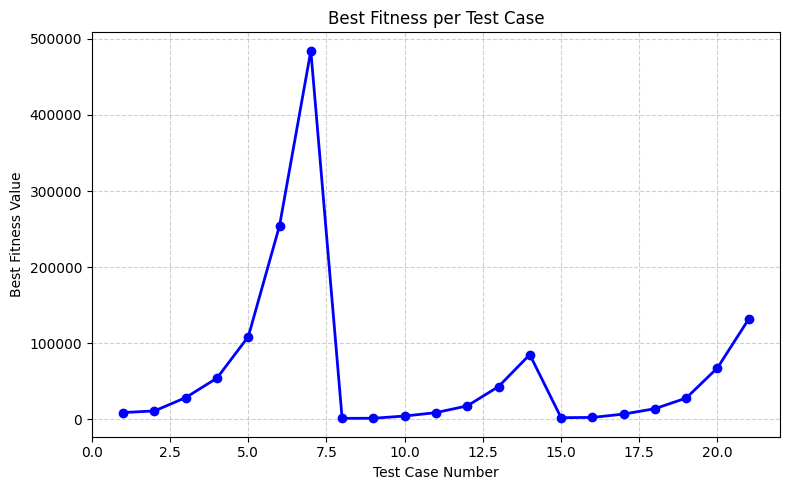

In [ ]:


def run_all_tests(folder_path):
    files = sorted([f for f in os.listdir(folder_path) if f.endswith('.txt')],
                   key=lambda x: int(x.split('.')[0]))

    all_best_fitness = []

    for file_name in files:
        file_path = os.path.join(folder_path, file_name)
        with open(file_path, 'r') as f:
            lines = f.readlines()

        n, capacity = map(int, lines[0].split())

        weights, values = [], []
        for line in lines[1:]:
            v, w = map(int, line.split())
            weights.append(w)
            values.append(v)

        weights = np.array(weights)
        values = np.array(values)

        print(f"\n==== Running {file_name} ====")
        
        best_sol, best_fitness, fitness_history = genetic_algorithm(
            values, weights, capacity,
            generation_size=60, generation=100
        )

        print(f"Best fitness for {file_name}: {best_fitness}")
        print(f"Selected items: {np.where(best_sol == 1)[0].tolist()}")

        all_best_fitness.append(best_fitness)

    
    plt.figure(figsize=(8,5))
    plt.plot(range(1, len(all_best_fitness)+1), all_best_fitness, marker='o', color='blue', linewidth=2)
    plt.title("Best Fitness per Test Case")
    plt.xlabel("Test Case Number")
    plt.ylabel("Best Fitness Value")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

run_all_tests("knapsack")


multiple point

In [83]:
def fitness(chromosome, values):
    return np.dot(chromosome, values)

def repair(chromosome, weights, values, capacity):
    total_weight = np.dot(chromosome, weights)
    if total_weight <= capacity:
        return chromosome
    
    idx = np.where(chromosome == 1)[0]
    ratios = values[idx] / weights[idx]
    sorted_idx = idx[np.argsort(ratios)]  
    for i in sorted_idx:
        chromosome[i] = 0
        total_weight = np.dot(chromosome, weights)
        if total_weight <= capacity:
            break
    return chromosome

def generate_population(values, weights, capacity, pop_size):
    n = len(values)
    population = []
    for _ in range(pop_size):
        chro = np.random.randint(0, 2, n)
        chro = repair(chro, weights, values, capacity)
        population.append(chro)
    return np.array(population)

def two_point_crossover(p1, p2):
    points = np.sort(np.random.choice(range(1, len(p1) - 1), 2, replace=False))
    a, b = points
    child1 = np.concatenate([p1[:a], p2[a:b], p1[b:]])
    child2 = np.concatenate([p2[:a], p1[a:b], p2[b:]])
    return child1, child2

def mutiation(chromosome, rate=0.03):
    for i in range(len(chromosome)):
        if np.random.rand() < rate:
            chromosome[i] = 1 - chromosome[i]
    return chromosome

def tournament_selection(population, fitnesses, k=5):
    selected = np.random.choice(len(population), k)
    best = selected[np.argmax(fitnesses[selected])]
    return population[best]

def genetic_algorithm(values, weights, capacity, generation_size=200, generation=800, mutation_rate=0.03):
    population = generate_population(values, weights, capacity, generation_size)
    best_sol = None
    best_fit = 0
    fitness_hist = []

    for gen in range(generation):
        fitnesses = np.array([fitness(ch, values) for ch in population])
        fitness_hist.append(np.max(fitnesses))
        
        elite_count = 3
        elite_idx = np.argsort(fitnesses)[-elite_count:]
        elites = [population[i].copy() for i in elite_idx]

        if np.max(fitnesses) > best_fit:
            best_fit = np.max(fitnesses)
            best_sol = population[np.argmax(fitnesses)].copy()

        new_population = elites.copy()
        while len(new_population) < generation_size:
            p1 = tournament_selection(population, fitnesses, k=5)
            p2 = tournament_selection(population, fitnesses, k=5)
            c1, c2 = sp_crossover(p1, p2)
            c1 = mutiation(c1, mutation_rate)
            c2 = mutiation(c2, mutation_rate)
            c1 = repair(c1, weights, values, capacity)
            c2 = repair(c2, weights, values, capacity)
            new_population += [c1, c2]
        
        population = np.array(new_population[:generation_size])
        if gen % 50 == 0:
            print(f"Generation {gen}, Best fitness = {best_fit}")

    return best_sol, best_fit, fitness_hist


==== Running 1.txt ====
Generation 0, Best fitness = 8556
Generation 50, Best fitness = 9147
Best fitness for 1.txt: 9147
Selected items: [6, 10, 13, 23, 25, 30, 32, 37, 38, 48, 53, 60]

==== Running 2.txt ====
Generation 0, Best fitness = 9927
Generation 50, Best fitness = 11238
Best fitness for 2.txt: 11238
Selected items: [6, 10, 23, 25, 32, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 151]

==== Running 3.txt ====
Generation 0, Best fitness = 22174
Generation 50, Best fitness = 28857
Best fitness for 3.txt: 28857
Selected items: [6, 10, 12, 13, 23, 25, 32, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 151, 215, 216, 249, 254, 269, 273, 281, 334, 347, 362, 373, 379, 382, 419, 421, 426, 446, 463, 469, 473, 476, 480, 493, 494]

==== Running 4.txt ====
Generation 0, Best fitness = 43749
Generation 50, Best fitness = 54166
Best fitness for 4.txt: 54447
Selected items: [6, 10, 12, 13, 23, 25, 32, 35, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 151, 215, 216, 236, 245, 249, 254, 269, 273

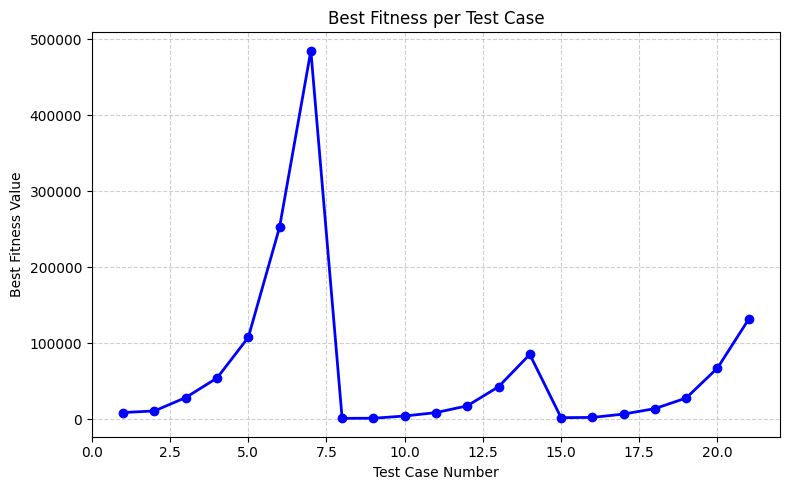

In [89]:


def run_all_tests(folder_path):
    files = sorted([f for f in os.listdir(folder_path) if f.endswith('.txt')],
                   key=lambda x: int(x.split('.')[0]))

    all_best_fitness = []

    for file_name in files:
        file_path = os.path.join(folder_path, file_name)
        with open(file_path, 'r') as f:
            lines = f.readlines()

        n, capacity = map(int, lines[0].split())

        weights, values = [], []
        for line in lines[1:]:
            v, w = map(int, line.split())
            weights.append(w)
            values.append(v)

        weights = np.array(weights)
        values = np.array(values)

        print(f"\n==== Running {file_name} ====")
        
        best_sol, best_fitness, fitness_history = genetic_algorithm(
            values, weights, capacity,
            generation_size=60, generation=100
        )

        print(f"Best fitness for {file_name}: {best_fitness}")
        print(f"Selected items: {np.where(best_sol == 1)[0].tolist()}")

        all_best_fitness.append(best_fitness)

    
    plt.figure(figsize=(8,5))
    plt.plot(range(1, len(all_best_fitness)+1), all_best_fitness, marker='o', color='blue', linewidth=2)
    plt.title("Best Fitness per Test Case")
    plt.xlabel("Test Case Number")
    plt.ylabel("Best Fitness Value")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

run_all_tests("knapsack")


uniform crossover

In [85]:
def fitness(chromosome, values):
    return np.dot(chromosome, values)

def repair(chromosome, weights, values, capacity):
    total_weight = np.dot(chromosome, weights)
    if total_weight <= capacity:
        return chromosome
    
    idx = np.where(chromosome == 1)[0]
    ratios = values[idx] / weights[idx]
    sorted_idx = idx[np.argsort(ratios)]  
    for i in sorted_idx:
        chromosome[i] = 0
        total_weight = np.dot(chromosome, weights)
        if total_weight <= capacity:
            break
    return chromosome

def generate_population(values, weights, capacity, pop_size):
    n = len(values)
    population = []
    for _ in range(pop_size):
        chro = np.random.randint(0, 2, n)
        chro = repair(chro, weights, values, capacity)
        population.append(chro)
    return np.array(population)

def uniform_crossover(p1, p2, prob=0.5):
    mask = np.random.rand(len(p1)) < prob
    child1 = np.where(mask, p1, p2)
    child2 = np.where(mask, p2, p1)
    return child1, child2


def mutiation(chromosome, rate=0.03):
    for i in range(len(chromosome)):
        if np.random.rand() < rate:
            chromosome[i] = 1 - chromosome[i]
    return chromosome

def tournament_selection(population, fitnesses, k=5):
    selected = np.random.choice(len(population), k)
    best = selected[np.argmax(fitnesses[selected])]
    return population[best]

def genetic_algorithm(values, weights, capacity, generation_size=200, generation=800, mutation_rate=0.03):
    population = generate_population(values, weights, capacity, generation_size)
    best_sol = None
    best_fit = 0
    fitness_hist = []

    for gen in range(generation):
        fitnesses = np.array([fitness(ch, values) for ch in population])
        fitness_hist.append(np.max(fitnesses))
        
        elite_count = 3
        elite_idx = np.argsort(fitnesses)[-elite_count:]
        elites = [population[i].copy() for i in elite_idx]

        if np.max(fitnesses) > best_fit:
            best_fit = np.max(fitnesses)
            best_sol = population[np.argmax(fitnesses)].copy()

        new_population = elites.copy()
        while len(new_population) < generation_size:
            p1 = tournament_selection(population, fitnesses, k=5)
            p2 = tournament_selection(population, fitnesses, k=5)
            c1, c2 = sp_crossover(p1, p2)
            c1 = mutiation(c1, mutation_rate)
            c2 = mutiation(c2, mutation_rate)
            c1 = repair(c1, weights, values, capacity)
            c2 = repair(c2, weights, values, capacity)
            new_population += [c1, c2]
        
        population = np.array(new_population[:generation_size])
        if gen % 50 == 0:
            print(f"Generation {gen}, Best fitness = {best_fit}")

    return best_sol, best_fit, fitness_hist


==== Running 1.txt ====
Generation 0, Best fitness = 7801
Generation 50, Best fitness = 8929
Best fitness for 1.txt: 8929
Selected items: [10, 12, 13, 23, 25, 32, 35, 37, 38, 48, 53, 60]

==== Running 2.txt ====
Generation 0, Best fitness = 9240
Generation 50, Best fitness = 11238
Best fitness for 2.txt: 11238
Selected items: [6, 10, 23, 25, 32, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 151]

==== Running 3.txt ====
Generation 0, Best fitness = 23149
Generation 50, Best fitness = 28834
Best fitness for 3.txt: 28834
Selected items: [6, 10, 13, 23, 25, 32, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 151, 215, 216, 236, 245, 249, 254, 269, 273, 281, 334, 347, 362, 373, 379, 382, 419, 421, 426, 446, 463, 469, 473, 476, 480, 493, 494]

==== Running 4.txt ====
Generation 0, Best fitness = 43511
Generation 50, Best fitness = 54236
Best fitness for 4.txt: 54264
Selected items: [6, 10, 12, 13, 23, 25, 32, 35, 37, 38, 48, 53, 60, 121, 134, 137, 146, 147, 151, 215, 216, 236, 245, 249, 254, 2

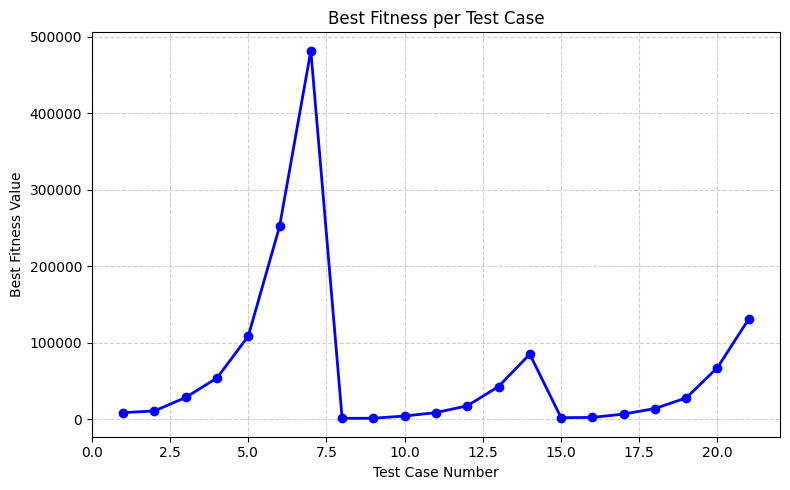

In [90]:


def run_all_tests(folder_path):
    files = sorted([f for f in os.listdir(folder_path) if f.endswith('.txt')],
                   key=lambda x: int(x.split('.')[0]))

    all_best_fitness = []

    for file_name in files:
        file_path = os.path.join(folder_path, file_name)
        with open(file_path, 'r') as f:
            lines = f.readlines()

        n, capacity = map(int, lines[0].split())

        weights, values = [], []
        for line in lines[1:]:
            v, w = map(int, line.split())
            weights.append(w)
            values.append(v)

        weights = np.array(weights)
        values = np.array(values)

        print(f"\n==== Running {file_name} ====")
        
        best_sol, best_fitness, fitness_history = genetic_algorithm(
            values, weights, capacity,
            generation_size=60, generation=100
        )

        print(f"Best fitness for {file_name}: {best_fitness}")
        print(f"Selected items: {np.where(best_sol == 1)[0].tolist()}")

        all_best_fitness.append(best_fitness)

    
    plt.figure(figsize=(8,5))
    plt.plot(range(1, len(all_best_fitness)+1), all_best_fitness, marker='o', color='blue', linewidth=2)
    plt.title("Best Fitness per Test Case")
    plt.xlabel("Test Case Number")
    plt.ylabel("Best Fitness Value")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

run_all_tests("knapsack")


Q1
The state space for a total of **n items** consists of all binary vectors (with elements 0 or 1), meaning there are **2ⁿ possible states**, and the solution space is **discrete**.


Q2 The reason **brute force** is not suitable is that the **state space is extremely large**, and it is **impossible to evaluate all possible states**.


Q4
**Increasing the Mutation Rate:**
Mutation introduces random changes to some bits (genes) in a chromosome, which leads to the creation of new and more diverse individuals in the population.
This helps prevent the population from becoming too uniform and allows the algorithm to escape from local optima.

**Using a Diverse Selection Strategy:**
Instead of selecting only the best individuals (which reduces diversity), we can use methods such as **Tournament Selection** or **Roulette Wheel Selection** so that even average chromosomes have a chance to survive.
This maintains genetic diversity and prevents the algorithm from converging too early on a specific region of the search space.


Q3 
The first method is single-point,
the second method is multiple-point,
and the third method is uniform-point.

According to the results, multiple-point seems to perform better.